# Predicting patient wait time with regression

I used the engineered patient features to predict wait time in minutes. I reserved 20% of the records for testing, compared ordinary linear regression with Ridge regression using cross-validation on the training data, and checked for overfitting using training, validation and test performance. I also compared the models against a baseline that always predicts the training-set mean.

Place `HealthData_Engineered.csv` beside this notebook before running all cells. Required packages: pandas, NumPy, Matplotlib, seaborn and scikit-learn.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
df = pd.read_csv(Path("HealthData_Engineered.csv"), dtype={"Patient Id": "string"}, keep_default_na=False)
df = df.replace(r"^\s*$", np.nan, regex=True)
print(f"Loaded {len(df):,} records and {len(df.columns)} columns.")
df.head()

Loaded 9,216 records and 23 columns.


,Patient Id,Patient Admission Date,Patient Admission Time,pt name,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Waittime,Gender original,Age group,Admission hour,Admission weekday,Admission month,Admission year,Weekend admission,Hour sin,Hour cos,Weekday sin,Weekday cos,Has referral,Admitted
0,780966113,2024-09-09,09:25:00,W. Breede,Female,63,African American,None,Not Admission,32,Female,50–64,9,0,9,2024,0,0.707107,-0.707107,0.0,1.0,0,0
1,714356722,2024-09-09,16:42:00,Y. Baldetti,Male,31,Asian,Orthopedics,Not Admission,22,Male,18–34,16,0,9,2024,0,-0.866025,-0.500000,0.0,1.0,1,0
2,571853714,2024-09-09,00:14:00,M. Semerad,Male,75,White,General Practice,Not Admission,16,Male,65+,0,0,9,2024,0,0.000000,1.000000,0.0,1.0,1,0
3,404439499,2024-09-09,20:33:00,K. Blaydes,Male,79,African American,General Practice,Admission,38,Male,65+,20,0,9,2024,0,-0.866025,0.500000,0.0,1.0,1,1
4,552515855,2024-09-09,19:25:00,F. Dickerson,Female,24,African American,None,Admission,36,Female,18–34,19,0,9,2024,0,-0.965926,0.258819,0.0,1.0,0,1


## Select the engineered features

I included age, age group, calendar features, cyclic hour/weekday features, the referral indicator, gender, race and referral department. I retained `unknown` as a gender category. I excluded names, IDs, original labels and raw dates/times from the predictors. I also excluded admission status and `Admitted` because their availability before waiting ends is unconfirmed. The outcome is `Patient Waittime` in minutes. I used the engineered dataset rather than the previously exported one-hot matrix so encoding and scaling can be fitted within training folds.

In [2]:
numeric_features = ["Patient Age", "Admission month", "Admission year", "Weekend admission",
                    "Hour sin", "Hour cos", "Weekday sin", "Weekday cos", "Has referral"]
categorical_features = ["Patient Gender", "Patient Race", "Department Referral", "Age group"]
X = df[numeric_features + categorical_features].copy()
y = pd.to_numeric(df["Patient Waittime"], errors="raise")
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="raise")
assert y.notna().all(), "The target contains missing values."
assert "Patient Waittime" not in X.columns
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Repeated patient IDs:", int(df["Patient Id"].duplicated().sum()))
print("Target range:", y.min(), "to", y.max(), "minutes")
X.head()

Missing predictor values: 0
Repeated patient IDs: 0
Target range: 10 to 60 minutes


,Patient Age,Admission month,Admission year,Weekend admission,Hour sin,Hour cos,Weekday sin,Weekday cos,Has referral,Patient Gender,Patient Race,Department Referral,Age group
0,63,9,2024,0,0.707107,-0.707107,0.0,1.0,0,Female,African American,None,50–64
1,31,9,2024,0,-0.866025,-0.500000,0.0,1.0,1,Male,Asian,Orthopedics,18–34
2,75,9,2024,0,0.000000,1.000000,0.0,1.0,1,Male,White,General Practice,65+
3,79,9,2024,0,-0.866025,0.500000,0.0,1.0,1,Male,African American,General Practice,65+
4,24,9,2024,0,-0.965926,0.258819,0.0,1.0,0,Female,African American,None,18–34


## Train/test split

I randomly assigned 80% of the records to training and 20% to testing using a fixed random seed. I used the training set for cross-validation and model selection and kept the test set untouched until final evaluation. This random split estimates performance on similar records; it does not establish future-period performance. If patients have repeated visits, a patient-group split would be needed to evaluate generalisation to unseen patients.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training: {len(X_train):,} records ({len(X_train)/len(X):.1%})")
print(f"Testing:  {len(X_test):,} records ({len(X_test)/len(X):.1%})")
assert set(X_train.index).isdisjoint(X_test.index)
assert not set(df.loc[X_train.index, "Patient Id"]).intersection(df.loc[X_test.index, "Patient Id"]), "Repeated patients span both sets; use a grouped split."

Training: 7,372 records (80.0%)
Testing:  1,844 records (20.0%)


## Preprocessing and regression

I fitted numeric imputation, scaling, categorical imputation and one-hot encoding inside a pipeline. This keeps the validation and test sets out of preprocessing estimates. I compared ordinary linear regression with Ridge regression, which penalises large coefficients. I selected the regression configuration with the lowest five-fold cross-validation RMSE on the training set. I included a wide range of Ridge penalties because the earlier EDA showed weak relationships.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
pipeline = Pipeline([("preprocess", preprocessor), ("regression", Ridge())])
parameter_grid = [
    {"regression": [LinearRegression()]},
    {"regression": [Ridge()], "regression__alpha": [0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]}
]
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, parameter_grid, scoring="neg_root_mean_squared_error",
                      cv=cv, return_train_score=True, n_jobs=1)
search.fit(X_train, y_train)
model = search.best_estimator_
print("Selected regression:", model.named_steps["regression"])
print(f"Best training CV RMSE: {-search.best_score_:.3f} minutes")

Selected regression: Ridge(alpha=100000)
Best training CV RMSE: 14.762 minutes


In [5]:
cv_results = pd.DataFrame({
    "Model": [str(p["regression"]) for p in search.cv_results_["params"]],
    "Alpha": [p.get("regression__alpha", np.nan) for p in search.cv_results_["params"]],
    "CV training RMSE": -search.cv_results_["mean_train_score"],
    "CV validation RMSE": -search.cv_results_["mean_test_score"],
    "CV validation RMSE SD": search.cv_results_["std_test_score"]
})
cv_results.sort_values("CV validation RMSE").round(3)

,Model,Alpha,CV training RMSE,CV validation RMSE,CV validation RMSE SD
7,Ridge(),100000.0,14.759,14.762,0.179
8,Ridge(),1000000.0,14.760,14.763,0.179
6,Ridge(),10000.0,14.751,14.764,0.177
5,Ridge(),1000.0,14.741,14.775,0.174
4,Ridge(),100.0,14.733,14.787,0.169
3,Ridge(),10.0,14.729,14.792,0.161
2,Ridge(),1.0,14.729,14.795,0.158
1,Ridge(),0.1,14.729,14.795,0.157
0,LinearRegression(),NaN,14.729,14.795,0.157


## Final evaluation and baseline comparison

I report MAE and RMSE in minutes; lower values are better. RMSE gives more weight to larger errors. R² measures improvement relative to predicting the evaluated set’s mean: 1 is perfect, around 0 indicates little explanatory power, and negative values indicate worse performance than that mean reference. The explicit baseline below uses only the training-set mean.

In [6]:
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

def regression_metrics(actual, predicted):
    return {"MAE (mins)": mean_absolute_error(actual, predicted),
            "RMSE (mins)": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

rows = []
for name, fitted_model in [("Mean baseline", baseline), ("Selected regression", model)]:
    for split, inputs, actual in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        rows.append({"Model": name, "Split": split,
                     **regression_metrics(actual, fitted_model.predict(inputs))})
metrics = pd.DataFrame(rows)
metrics.round(4)

,Model,Split,MAE (mins),RMSE (mins),R2
0,Mean baseline,Train,12.8010,14.7606,0.0000
1,Mean baseline,Test,12.5949,14.6337,-0.0027
2,Selected regression,Train,12.7994,14.7590,0.0002
3,Selected regression,Test,12.5923,14.6321,-0.0025


## Check for overfitting

I compared training and test errors and reviewed the training-versus-validation gap across the cross-validation results. A much lower training error alongside worse validation/test errors would suggest overfitting. Similar errors do not establish a useful model: both can be poor. I use learning curves below to inspect this distinction rather than applying an arbitrary pass/fail threshold.

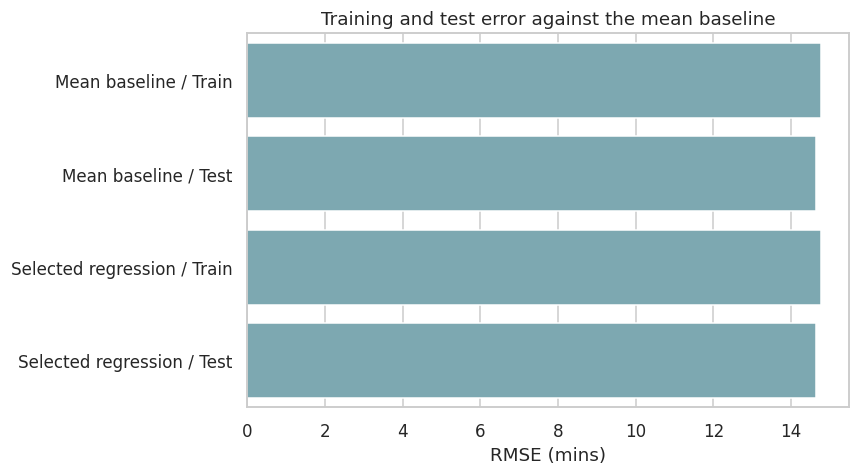

Training RMSE: 14.759 minutes
Test RMSE: 14.632 minutes
Test minus training RMSE: -0.127 minutes
Test baseline RMSE: 14.634 minutes
RMSE improvement over baseline: +0.011%
Test R²: -0.00253


In [7]:
train_prediction = model.predict(X_train)
test_prediction = model.predict(X_test)
train_rmse = np.sqrt(mean_squared_error(y_train, train_prediction))
test_rmse = np.sqrt(mean_squared_error(y_test, test_prediction))
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline.predict(X_test)))
print(f"Training RMSE: {train_rmse:.3f} minutes")
print(f"Test RMSE: {test_rmse:.3f} minutes")
print(f"Test minus training RMSE: {test_rmse - train_rmse:+.3f} minutes")
print(f"Test baseline RMSE: {baseline_rmse:.3f} minutes")
print(f"RMSE improvement over baseline: {100*(baseline_rmse-test_rmse)/baseline_rmse:+.3f}%")
print(f"Test R²: {r2_score(y_test, test_prediction):.5f}")
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_metrics = metrics.assign(Label=metrics["Model"] + " / " + metrics["Split"])
sns.barplot(data=plot_metrics, y="Label", x="RMSE (mins)", color="#74ADBA", ax=ax)
ax.set(title="Training and test error against the mean baseline", ylabel="", xlabel="RMSE (mins)")
fig.tight_layout()
plt.show()

## Learning curves using training data only

I refitted the selected configuration using increasing training subsets and five-fold validation. A large persistent gap between the curves would indicate overfitting. Similar high errors suggest limited signal or underfitting. Because this configuration was selected using the training set, these curves are diagnostic rather than an independent final performance estimate.

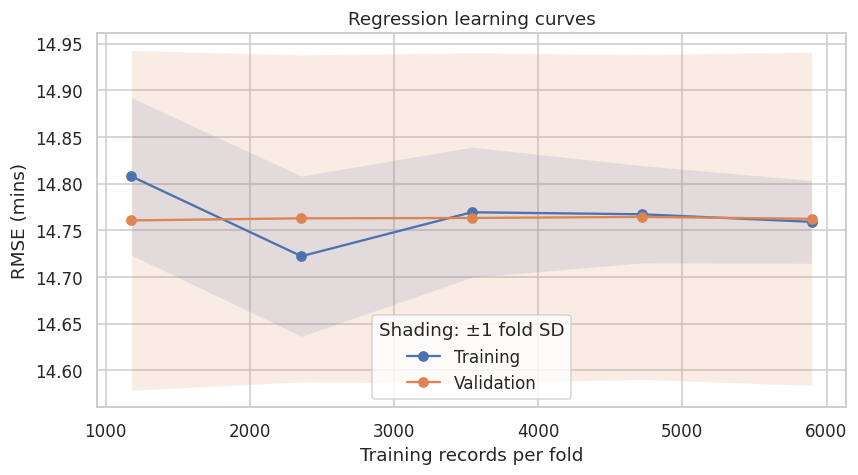

,Training records per fold,Mean training RMSE,Mean validation RMSE,Validation RMSE SD
0,1179,14.808,14.761,0.182
1,2358,14.722,14.763,0.175
2,3538,14.769,14.763,0.177
3,4717,14.767,14.764,0.174
4,5897,14.759,14.762,0.179


In [8]:
sizes, train_scores, validation_scores = learning_curve(
    model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True,
    random_state=RANDOM_STATE, n_jobs=1
)
train_errors = -train_scores
validation_errors = -validation_scores
learning_summary = pd.DataFrame({"Training records per fold": sizes,
    "Mean training RMSE": train_errors.mean(axis=1),
    "Mean validation RMSE": validation_errors.mean(axis=1),
    "Validation RMSE SD": validation_errors.std(axis=1)})
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, values in [("Training", train_errors), ("Validation", validation_errors)]:
    mean, sd = values.mean(axis=1), values.std(axis=1)
    ax.plot(sizes, mean, "o-", label=label)
    ax.fill_between(sizes, mean-sd, mean+sd, alpha=0.15)
ax.set(title="Regression learning curves", xlabel="Training records per fold", ylabel="RMSE (mins)")
ax.legend(title="Shading: ±1 fold SD")
fig.tight_layout()
plt.show()
learning_summary.round(3)

## Test-set prediction and residual plots

I plotted observed versus predicted wait times and residuals, defined as observed minus predicted wait time. Predictions close to the diagonal would indicate accurate estimates. Predictions clustered around the mean indicate that the model captures little of the variation between patients.

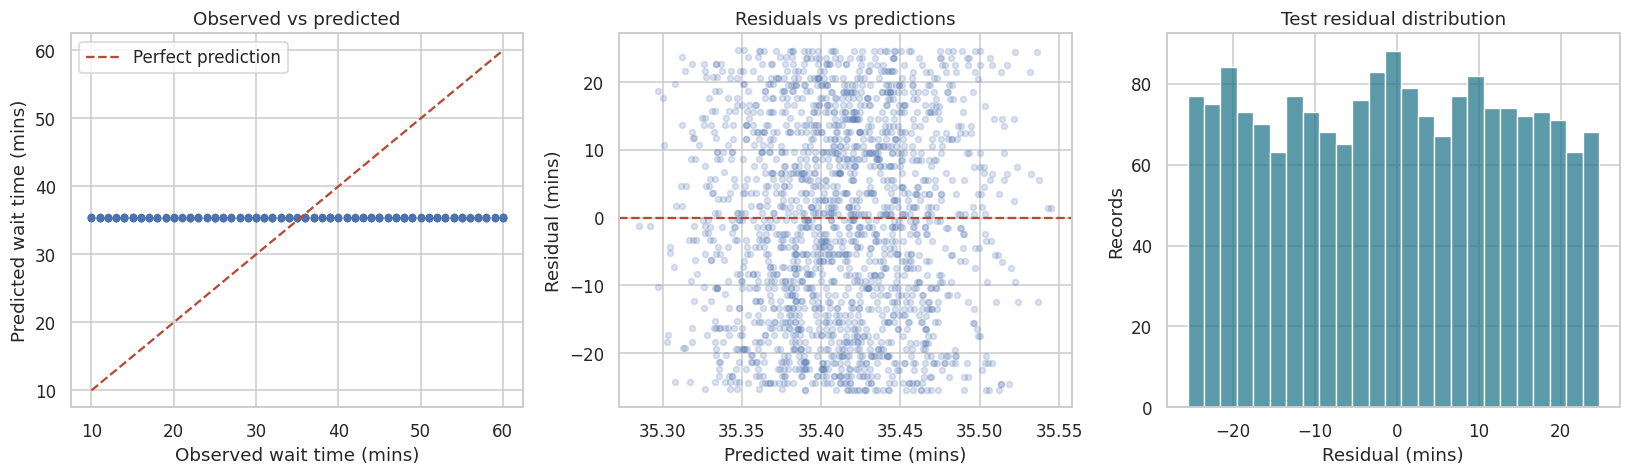

In [9]:
residuals = y_test.to_numpy() - test_prediction
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(y_test, test_prediction, alpha=0.2, s=15)
limits = [min(y_test.min(), test_prediction.min()), max(y_test.max(), test_prediction.max())]
axes[0].plot(limits, limits, "--", color="#B64B35", label="Perfect prediction")
axes[0].set(xlabel="Observed wait time (mins)", ylabel="Predicted wait time (mins)", title="Observed vs predicted")
axes[0].legend()
axes[1].scatter(test_prediction, residuals, alpha=0.2, s=15)
axes[1].axhline(0, color="#B64B35", linestyle="--")
axes[1].set(xlabel="Predicted wait time (mins)", ylabel="Residual (mins)", title="Residuals vs predictions")
sns.histplot(residuals, bins=25, ax=axes[2], color="#26778C")
axes[2].set(xlabel="Residual (mins)", ylabel="Records", title="Test residual distribution")
fig.tight_layout()
plt.show()

In [10]:
prediction_examples = pd.DataFrame({
    "Observed wait time (mins)": y_test,
    "Predicted wait time (mins)": test_prediction,
    "Absolute error (mins)": np.abs(y_test.to_numpy()-test_prediction)
})
prediction_examples.head(10).round(2)

,Observed wait time (mins),Predicted wait time (mins),Absolute error (mins)
4502,45,35.43,9.57
3130,40,35.33,4.67
7559,55,35.40,19.60
3685,58,35.48,22.52
1790,18,35.43,17.43
5840,49,35.45,13.55
8486,49,35.49,13.51
7231,31,35.43,4.43
8366,37,35.41,1.59
7379,36,35.46,0.54


## Interpretation and conclusion

I selected **Ridge(alpha=100000)** using five-fold cross-validation on the training set. The model achieved a training RMSE of **14.759 minutes** and a test RMSE of **14.632 minutes**, a difference of **-0.127 minutes**. I found no large train–test error gap indicating substantial overfitting in the selected model.

The mean baseline achieved a test RMSE of **14.634 minutes**, compared with **14.632 minutes** for the regression model. The test R² was **-0.00253**. The regression offers little improvement over the mean baseline and explains almost none of the differences in individual wait times. Similar training and test errors therefore reflect limited predictive signal, not strong predictive performance.

My conclusion applies to this random split and these features. The weak relationships found during EDA are consistent with these results. I have not established that the features cause changes in wait time or that the model will perform well on future admissions.